In [1]:
from anemone.physics import *
from anemone import constants as c
import torch
import matplotlib.pyplot as plt
import numpy as np

In [2]:
def transverse_electric_field_coefficients(sigma, thickness, omega, wave_length, mu=c.mu0, epsilon=c.epsilon0):
    """ for computing the field components at depth
        the size of the matrix can and should be reduced by 2.
        There are 2*n_layers of equations, but parameters in the first and last layers are known and can therefore be simplified.

    """
    if isinstance(mu, float):
        mu = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*mu
    if isinstance(epsilon, float):
        epsilon = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*epsilon

    n_layers=len(sigma)

    lambda2 = wave_length**2
    
    u0 = torch.sqrt(lambda2 - omega**2 * c.mu0*c.epsilon0 + 0j)
    
    k2 = calc_wavenumber(sigma, omega, mu=mu, epsilon=epsilon, sqrt=False)

    u_n = torch.sqrt(lambda2 - k2)
    euh_p = torch.exp(u_n[:-1]*thickness)
    euh_m = 1./euh_p

    Amat = torch.zeros(u0.squeeze().shape+(2*n_layers, 2*n_layers), dtype=torch.complex128, device=sigma.device)
    Bmat = torch.zeros((2*n_layers,), dtype=torch.complex128, device=sigma.device)

    Amat[..., 0,0], Amat[..., 0,1], Amat[..., 0,2], Amat[..., 0,3] =  1.,  1.,    -1., -1.
    Amat[..., 1,0], Amat[..., 1,1], Amat[..., 1,2], Amat[..., 1,3] = -u0,  u0, u_n[0], -u_n[0]
    
    for i in range(1, n_layers-1):
        Amat[..., i*2,i*2]   = euh_m[i-1]
        Amat[..., i*2,i*2+1] = euh_p[i-1]
        Amat[..., i*2,i*2+2] = -1.
        Amat[..., i*2,i*2+3] = -1.


        Amat[..., i*2+1,i*2  ] = -u_n[i-1]*euh_m[i-1]
        Amat[..., i*2+1,i*2+1] =  u_n[i-1]*euh_p[i-1]
        Amat[..., i*2+1,i*2+2] =  u_n[i]
        Amat[..., i*2+1,i*2+3] = -u_n[i]

    Amat[..., -2,-1] = 1.
    Amat[..., -1, 0] = 1.

    Bmat[-1] = 1.

    AB = torch.linalg.solve(Amat, Bmat)
    return AB[..., ::2], AB[..., 1::2]

In [399]:
def transverse_electric_field_coefficients_nbc(sigma, thickness, omega, wave_length, mu=c.mu0, epsilon=c.epsilon0):
    """ for computing the field components at depth
        the size of the matrix can and should be reduced by 2.
        There are 2*n_layers of equations, but parameters in the first and last layers are known and can therefore be simplified.

    """
    if isinstance(mu, float):
        mu = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*mu
    if isinstance(epsilon, float):
        epsilon = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*epsilon

    n_layers=len(sigma)

    lambda2 = (wave_length+0j)**2
    
    u0 = torch.sqrt(lambda2 - omega**2 * c.mu0*c.epsilon0 + 0j)
    
    k2 = calc_wavenumber(sigma, omega, mu=mu, epsilon=epsilon, sqrt=False)

    u_n = torch.sqrt(lambda2 - k2)
    euh_m = torch.exp(-u_n[:-1]*thickness)
    euh_p = 1./euh_m
    zn = calc_zy(sigma, omega)[0]
    un_zn = u_n / zn
    

    Fn_m = torch.zeros((n_layers+1,)+u0.squeeze().shape, dtype=torch.complex128, device=sigma.device)
    Fn_p = torch.zeros_like(Fn_m)
    
    Fn_p[-1] = 1.

    for i in range(n_layers-1, 0, -1):
        unznp1_unzn = un_zn[i]/un_zn[i-1]
        Fn_m[i] = 0.5*euh_m[i-1]*((1+(unznp1_unzn))*Fn_m[i+1] + (1-(unznp1_unzn))*Fn_p[i+1])
        Fn_p[i] = 0.5*euh_p[i-1]*((1-(unznp1_unzn))*Fn_m[i+1] + (1+(unznp1_unzn))*Fn_p[i+1])
    
    unznp1_unzn = un_zn[0]/(u0/calc_zy(0., omega)[0])
    Fn_m[0] = 0.5*((1+(unznp1_unzn))*Fn_m[1] + (1-(unznp1_unzn))*Fn_p[1])
    Fn_p[0] = 0.5*((1-(unznp1_unzn))*Fn_m[1] + (1+(unznp1_unzn))*Fn_p[1])

    return Fn_m/Fn_p[0], Fn_p/Fn_p[0]

In [390]:
def transverse_magnetic_field_coefficients(sigma, thickness, omega, wave_length, mu=c.mu0, epsilon=c.epsilon0):
    """ for computing the field components at depth
        the size of the matrix can and should be reduced by 2.
        There are 2*n_layers of equations, but parameters in the first and last layers are known and can therefore be simplified.

    """
    if isinstance(mu, float):
        mu = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*mu
    if isinstance(epsilon, float):
        epsilon = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*epsilon

    n_layers=len(sigma)

    lambda2 = wave_length**2
    
    u0 = torch.sqrt(lambda2 - omega**2 * c.mu0*c.epsilon0 + 0j)
    
    k2 = calc_wavenumber(sigma, omega, mu=mu, epsilon=epsilon, sqrt=False)
    zhat,yhat = calc_zy(sigma, omega)
    yhat0 = yhat[0]-yhat[0].real

    print(yhat.shape)

    u_n = torch.sqrt(lambda2 - k2)
    euh_p = torch.exp(u_n[:-1]*thickness)
    euh_m = 1./euh_p

    Amat = torch.zeros(u0.squeeze().shape+(2*n_layers, 2*n_layers), dtype=torch.complex128, device=sigma.device)
    Bmat = torch.zeros((2*n_layers,), dtype=torch.complex128, device=sigma.device)

    Amat[..., 0,0], Amat[..., 0,1], Amat[..., 0,2], Amat[..., 0,3] =  1.,  1.,    -1., -1.
    Amat[..., 1,0], Amat[..., 1,1], Amat[..., 1,2], Amat[..., 1,3] = -u0/yhat0,  u0/yhat0, u_n[0]/yhat[0], -u_n[0]/yhat[0]
    
    for i in range(1, n_layers-1):
        Amat[..., i*2,i*2]   = euh_m[i-1]
        Amat[..., i*2,i*2+1] = euh_p[i-1]
        Amat[..., i*2,i*2+2] = -1.
        Amat[..., i*2,i*2+3] = -1.


        Amat[..., i*2+1,i*2  ] = -u_n[i-1]*euh_m[i-1]/yhat[i-1]
        Amat[..., i*2+1,i*2+1] =  u_n[i-1]*euh_p[i-1]/yhat[i-1]
        Amat[..., i*2+1,i*2+2] =  u_n[i]/yhat[i]
        Amat[..., i*2+1,i*2+3] = -u_n[i]/yhat[i]

    Amat[..., -2,-1] = 1.
    Amat[..., -1, 0] = 1.

    Bmat[-1] = 1.

    AB = torch.linalg.solve(Amat, Bmat)
    return AB[..., ::2], AB[..., 1::2]

In [400]:
sigma = 10**np.random.uniform(-3, 1, 5)
sigma = 1./np.array([40, 80, 200, 80])
sigma = torch.from_numpy(sigma).to(torch.float64)
thick = torch.tensor([40, 40, 40])
thick_z = torch.zeros(len(sigma)+1)
thick_z[1:-1] = thick
thick_z[-1] = thick[-1]

# omega = torch.tensor([2000], dtype=torch.float64)
# lamda = torch.tensor([0.1], dtype=torch.float64)

omega = torch.logspace(1,6, 101, dtype=torch.float64)
lamda = torch.logspace(-2,4, 201, dtype=torch.float64)

sigma = sigma[:, None, None].to(torch.complex128)
thick = thick[:, None, None].to(torch.complex128)
# thick_z = thick_z[:,None, None].to(torch.complex128)
omega = omega[None, :, None].to(torch.complex128)
lamda = lamda[None, None, :].to(torch.complex128)


In [401]:
A,B = transverse_electric_field_coefficients(sigma, thick, omega, lamda)

In [402]:
Fn_m, Fn_p = transverse_electric_field_coefficients_nbc(sigma, thick, omega, lamda)

In [403]:
rte = refl_transverse_electric(sigma, thick, omega, lamda)

In [404]:
rtm = refl_transverse_magnetic(sigma, thick, omega, lamda)

In [405]:
rte0 = -rte
#rteN = -B[..., 0]
rteN = -Fn_m[0]

C:\Users\au646858\AppData\Local\Temp\ipykernel_12872\2337917862.py:3: RuntimeWarning: invalid value encountered in log10
  pcm = axs[0,0].pcolor(np.log10(rteN.real.squeeze()), cmap='rainbow')
C:\Users\au646858\AppData\Local\Temp\ipykernel_12872\2337917862.py:5: RuntimeWarning: invalid value encountered in log10
  pcm = axs[1,0].pcolor(np.log10(rte0.real.squeeze()), cmap='rainbow')
C:\Users\au646858\AppData\Local\Temp\ipykernel_12872\2337917862.py:7: RuntimeWarning: divide by zero encountered in log10
  axs[2,0].pcolor(np.log10(np.abs((rteN.real.squeeze()-rte0.real.squeeze())/rte0.real.squeeze())), vmin=-6, vmax=-1, cmap='rainbow')
C:\Users\au646858\AppData\Local\Temp\ipykernel_12872\2337917862.py:8: MatplotlibDeprecationWarning: Getting the array from a PolyQuadMesh will return the full array in the future (uncompressed). To get this behavior now set the PolyQuadMesh with a 2D array .set_array(data2d).
  plt.colorbar(pcm, ax=axs[2,0])
C:\Users\au646858\AppData\Local\Temp\ipykernel_1287

Text(0.5, 0.98, 'reflection coefficient for transverse electric field')

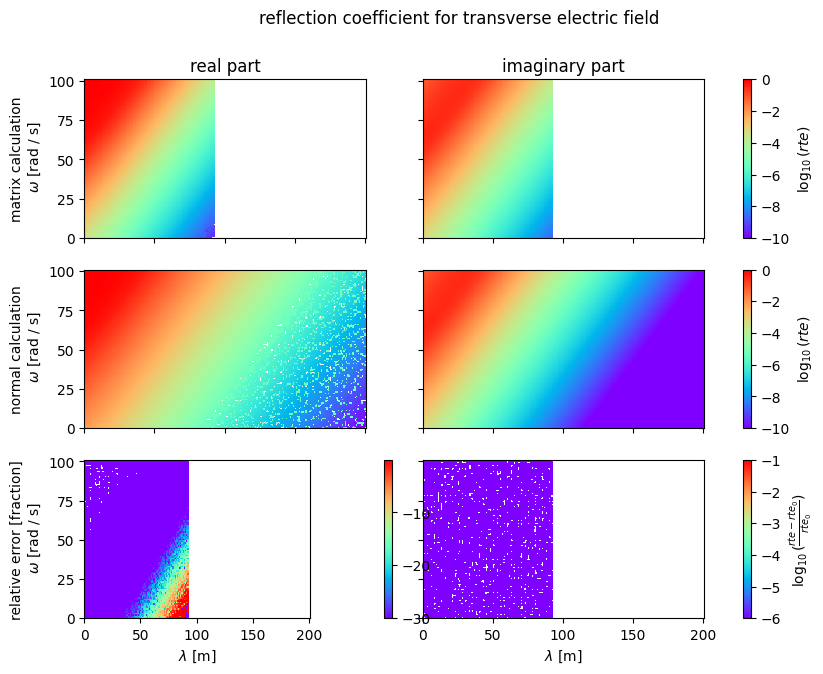

In [406]:
x,y = lamda.squeeze().real, omega.squeeze().real
fig,axs = plt.subplots(3,2, sharex=True, sharey=True, figsize=(10,7))
pcm = axs[0,0].pcolor(np.log10(rteN.real.squeeze()), cmap='rainbow')
# plt.colorbar(pcm, ax=axs[0,0])
pcm = axs[1,0].pcolor(np.log10(rte0.real.squeeze()), cmap='rainbow')
# plt.colorbar(pcm, ax=axs[1,0])
axs[2,0].pcolor(np.log10(np.abs((rteN.real.squeeze()-rte0.real.squeeze())/rte0.real.squeeze())), vmin=-6, vmax=-1, cmap='rainbow')
plt.colorbar(pcm, ax=axs[2,0])


pcm = axs[0,1].pcolor(np.log10(rteN.imag.squeeze()), vmin=-10, vmax=0, cmap='rainbow')
plt.colorbar(pcm, ax=axs[0,:], label='$\\log_{10}(rte)$')
pcm = axs[1,1].pcolor(np.log10(rte0.imag.squeeze()), vmin=-10, vmax=0, cmap='rainbow')
plt.colorbar(pcm, ax=axs[1,:], label='$\\log_{10}(rte)$')
pcm = axs[2,1].pcolor(np.log10(np.abs((rteN.imag.squeeze()-rte0.imag.squeeze())/rte0.imag.squeeze())), vmin=-6, vmax=-1, cmap='rainbow')
plt.colorbar(pcm, ax=axs[2,:], label='$\\log_{10}(\\frac{rte-rte_0}{rte_0})$')


axs[0,0].set_ylabel('matrix calculation\n $\\omega$ [rad / s]')
axs[1,0].set_ylabel('normal calculation\n $\\omega$ [rad / s]')
axs[2,0].set_ylabel('relative error [fraction]\n $\\omega$ [rad / s]')
axs[2,0].set_xlabel('$\\lambda$ [m]')
axs[2,1].set_xlabel('$\\lambda$ [m]')
axs[0,0].set_title('real part')
axs[0,1].set_title('imaginary part')

fig.suptitle('reflection coefficient for transverse electric field')
# plt.tight_layout()

C:\Users\au646858\AppData\Local\Temp\ipykernel_12872\1110808979.py:5: RuntimeWarning: invalid value encountered in log10
  pcm = axs[1,0].pcolor(x,y, np.log10(rte0.real.squeeze()), vmin=-10, vmax=0, cmap='rainbow')
C:\Users\au646858\AppData\Local\Temp\ipykernel_12872\1110808979.py:7: RuntimeWarning: divide by zero encountered in log10
  pcm = axs[2,0].pcolor(x,y, np.log10(np.abs((rteN.real.squeeze()-rte0.real.squeeze())/rte0.real.squeeze())), vmin=-6, vmax=-1, cmap='rainbow')
C:\Users\au646858\AppData\Local\Temp\ipykernel_12872\1110808979.py:13: MatplotlibDeprecationWarning: Getting the array from a PolyQuadMesh will return the full array in the future (uncompressed). To get this behavior now set the PolyQuadMesh with a 2D array .set_array(data2d).
  plt.colorbar(pcm, ax=axs[0,:], label='$\\log_{10}(rte)$')
C:\Users\au646858\AppData\Local\Temp\ipykernel_12872\1110808979.py:16: RuntimeWarning: divide by zero encountered in log10
  pcm = axs[2,1].pcolor(x,y, np.log10(np.abs((rteN.imag.sq

Text(0.5, 0.98, 'reflection coefficient for transverse electric field')

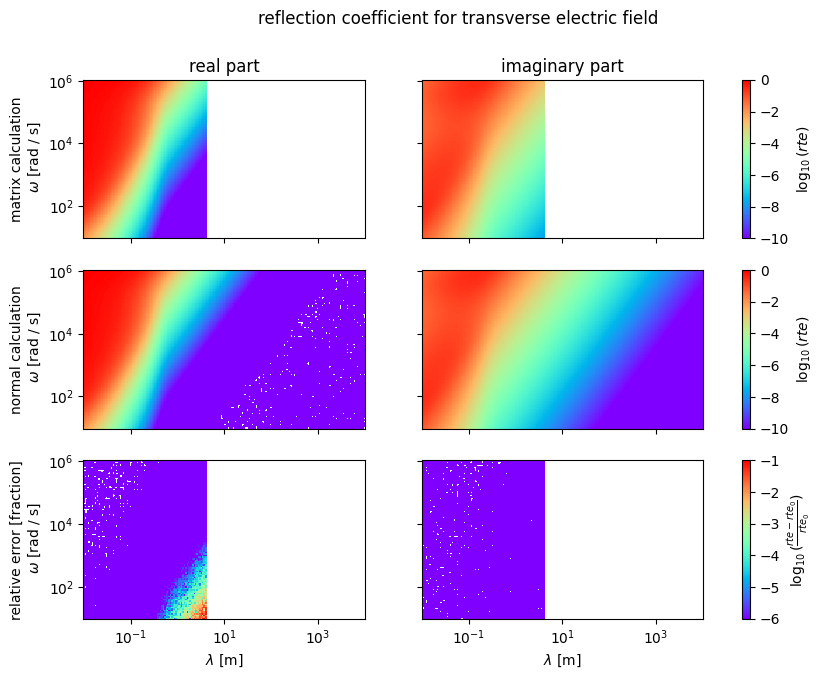

In [314]:
x,y = lamda.squeeze().real, omega.squeeze().real
fig,axs = plt.subplots(3,2, sharex=True, sharey=True, figsize=(10,7))
pcm = axs[0,0].pcolor(x,y, np.log10(rteN.real.squeeze()), vmin=-10, vmax=0, cmap='rainbow')
# plt.colorbar(pcm, ax=axs[0,0])
pcm = axs[1,0].pcolor(x,y, np.log10(rte0.real.squeeze()), vmin=-10, vmax=0, cmap='rainbow')
# plt.colorbar(pcm, ax=axs[1,0])
pcm = axs[2,0].pcolor(x,y, np.log10(np.abs((rteN.real.squeeze()-rte0.real.squeeze())/rte0.real.squeeze())), vmin=-6, vmax=-1, cmap='rainbow')
# plt.colorbar(pcm, ax=axs[2,0])
axs[2,0].set_xscale('log'); axs[2,0].set_yscale('log')


pcm = axs[0,1].pcolor(x,y, np.log10(rteN.imag.squeeze()), vmin=-10, vmax=0, cmap='rainbow')
plt.colorbar(pcm, ax=axs[0,:], label='$\\log_{10}(rte)$')
pcm = axs[1,1].pcolor(x,y, np.log10(rte0.imag.squeeze()), vmin=-10, vmax=0, cmap='rainbow')
plt.colorbar(pcm, ax=axs[1,:], label='$\\log_{10}(rte)$')
pcm = axs[2,1].pcolor(x,y, np.log10(np.abs((rteN.imag.squeeze()-rte0.imag.squeeze())/rte0.imag.squeeze())), vmin=-6, vmax=-1, cmap='rainbow')
plt.colorbar(pcm, ax=axs[2,:], label='$\\log_{10}(\\frac{rte-rte_0}{rte_0})$')
axs[2,1].set_xscale('log'); axs[2,1].set_yscale('log')

axs[0,0].set_ylabel('matrix calculation\n $\\omega$ [rad / s]')
axs[1,0].set_ylabel('normal calculation\n $\\omega$ [rad / s]')
axs[2,0].set_ylabel('relative error [fraction]\n $\\omega$ [rad / s]')
axs[2,0].set_xlabel('$\\lambda$ [m]')
axs[2,1].set_xlabel('$\\lambda$ [m]')
axs[0,0].set_title('real part')
axs[0,1].set_title('imaginary part')

fig.suptitle('reflection coefficient for transverse electric field')
# plt.tight_layout()

In [26]:
A,B = transverse_magnetic_field_coefficients(sigma, thick, omega, lamda)

torch.Size([5, 101, 1])


torch.Size([5, 101, 1])


C:\Users\au646858\AppData\Local\Temp\ipykernel_28524\3829780426.py:12: RuntimeWarning: divide by zero encountered in log10
  pcm = axs[2,0].pcolor(x,y, np.log10(np.abs((rteN.real.squeeze()-rte0.real.squeeze())/rte0.real.squeeze())), vmin=-6, vmax=-1, cmap='rainbow')
C:\Users\au646858\AppData\Local\Temp\ipykernel_28524\3829780426.py:20: MatplotlibDeprecationWarning: Getting the array from a PolyQuadMesh will return the full array in the future (uncompressed). To get this behavior now set the PolyQuadMesh with a 2D array .set_array(data2d).
  plt.colorbar(pcm, ax=axs[0,:], label='$\\log_{10}(rte)$')
C:\Users\au646858\AppData\Local\Temp\ipykernel_28524\3829780426.py:23: RuntimeWarning: divide by zero encountered in log10
  pcm = axs[2,1].pcolor(x,y, np.log10(np.abs((rteN.imag.squeeze()-rte0.imag.squeeze())/rte0.imag.squeeze())), vmin=-6, vmax=-1, cmap='rainbow')
C:\Users\au646858\AppData\Local\Temp\ipykernel_28524\3829780426.py:24: MatplotlibDeprecationWarning: Getting the array from a Po

Text(0.5, 0.98, 'reflection coefficient for transverse magnetic field')

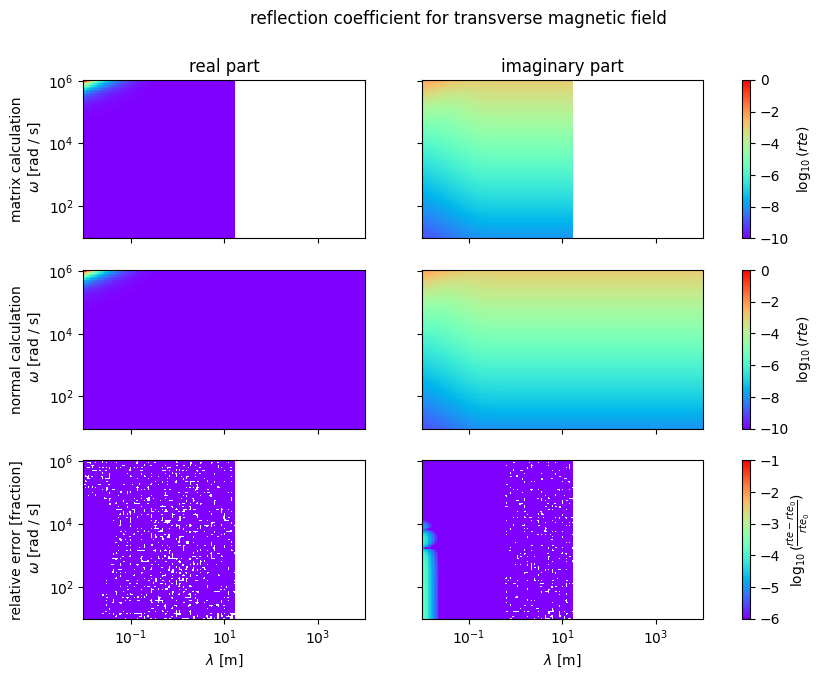

In [30]:
A,B = transverse_magnetic_field_coefficients(sigma, thick, omega, lamda)
rtm = refl_transverse_magnetic(sigma, thick, omega, lamda)
rte0 =  rtm
rteN =  B[..., 0]

x,y = lamda.squeeze().real, omega.squeeze().real
fig,axs = plt.subplots(3,2, sharex=True, sharey=True, figsize=(10,7))
pcm = axs[0,0].pcolor(x,y, np.log10(rteN.real.squeeze()), cmap='rainbow')
# plt.colorbar(pcm, ax=axs[0,0])
pcm = axs[1,0].pcolor(x,y, np.log10(rte0.real.squeeze()), cmap='rainbow')
# plt.colorbar(pcm, ax=axs[1,0])
pcm = axs[2,0].pcolor(x,y, np.log10(np.abs((rteN.real.squeeze()-rte0.real.squeeze())/rte0.real.squeeze())), vmin=-6, vmax=-1, cmap='rainbow')
# plt.colorbar(pcm, ax=axs[2,0])
axs[2,0].set_xscale('log'); axs[2,0].set_yscale('log')

rte0 =  -rtm
rteN =  -B[..., 0]

pcm = axs[0,1].pcolor(x,y, np.log10(rteN.imag.squeeze()), vmin=-10, vmax=0, cmap='rainbow')
plt.colorbar(pcm, ax=axs[0,:], label='$\\log_{10}(rte)$')
pcm = axs[1,1].pcolor(x,y, np.log10(rte0.imag.squeeze()), vmin=-10, vmax=0, cmap='rainbow')
plt.colorbar(pcm, ax=axs[1,:], label='$\\log_{10}(rte)$')
pcm = axs[2,1].pcolor(x,y, np.log10(np.abs((rteN.imag.squeeze()-rte0.imag.squeeze())/rte0.imag.squeeze())), vmin=-6, vmax=-1, cmap='rainbow')
plt.colorbar(pcm, ax=axs[2,:], label='$\\log_{10}(\\frac{rte-rte_0}{rte_0})$')
axs[2,1].set_xscale('log'); axs[2,1].set_yscale('log')

axs[0,0].set_ylabel('matrix calculation\n $\\omega$ [rad / s]')
axs[1,0].set_ylabel('normal calculation\n $\\omega$ [rad / s]')
axs[2,0].set_ylabel('relative error [fraction]\n $\\omega$ [rad / s]')
axs[2,0].set_xlabel('$\\lambda$ [m]')
axs[2,1].set_xlabel('$\\lambda$ [m]')
axs[0,0].set_title('real part')
axs[0,1].set_title('imaginary part')

fig.suptitle('reflection coefficient for transverse magnetic field')
# plt.tight_layout()